# Rule-based matching

Precision, recall and F1 on the validation labels, threshold chosen per matcher.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
matching = pd.concat([pd.read_csv(f"results/{run}/matching.csv") for run in ["first_pass", "final"]])
matching[["run", "pair", "matcher", "threshold", "P", "R", "F1", "corr", "seconds"]]

,run,pair,matcher,threshold,P,R,F1,corr,seconds
0,first_pass,wikidata-ror,name Levenshtein,0.35,0.643,0.838,0.728,358503,83.4
1,first_pass,wikidata-ror,name Jaro-Winkler,0.55,0.611,0.986,0.755,683218,82.1
2,first_pass,wikidata-ror,name Jaccard (words),0.30,0.644,0.739,0.689,208352,91.8
3,first_pass,wikidata-ror,"best of all names, Jaro-Winkler",0.30,0.601,0.986,0.747,755511,152.6
4,first_pass,wikidata-ror,"best of all names, Jaccard",0.30,0.621,0.901,0.736,334185,302.1
5,first_pass,wikidata-ror,rule: names 0.8 + country 0.2,0.75,0.624,0.937,0.749,398071,157.1
6,first_pass,wikidata-ror,rule: names 0.5 + country 0.2 + domain 0.3,0.70,0.826,0.901,0.862,16134,164.8
7,first_pass,wikidata-ror,rule: names 0.6 + country 0.1 + domain 0.3,0.70,0.826,0.901,0.862,16130,159.2
8,first_pass,wikidata-ror,rule: names + country + domain + city,0.70,0.929,0.824,0.873,13892,167.7
9,first_pass,wikidata-ror,"rule: all attributes (+ year, position)",0.60,0.842,0.937,0.887,39596,195.3


In [3]:
def plot_matching(df, run):
    part_all = df[df["run"] == run]
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * part_all["matcher"].nunique() + 1.5), sharey=True)
    for ax, pair in zip(axes, PAIRS):
        part = part_all[part_all["pair"] == pair].set_index("matcher")[["P", "R", "F1"]]
        part.plot.barh(ax=ax, width=0.8, legend=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"{run}: {pair}")
        ax.set_ylabel("")
    fig.legend(["P", "R", "F1"], loc="upper center", ncol=3)
    plt.tight_layout(rect=(0, 0, 1, 0.93))

## First pass: two rules on the original data

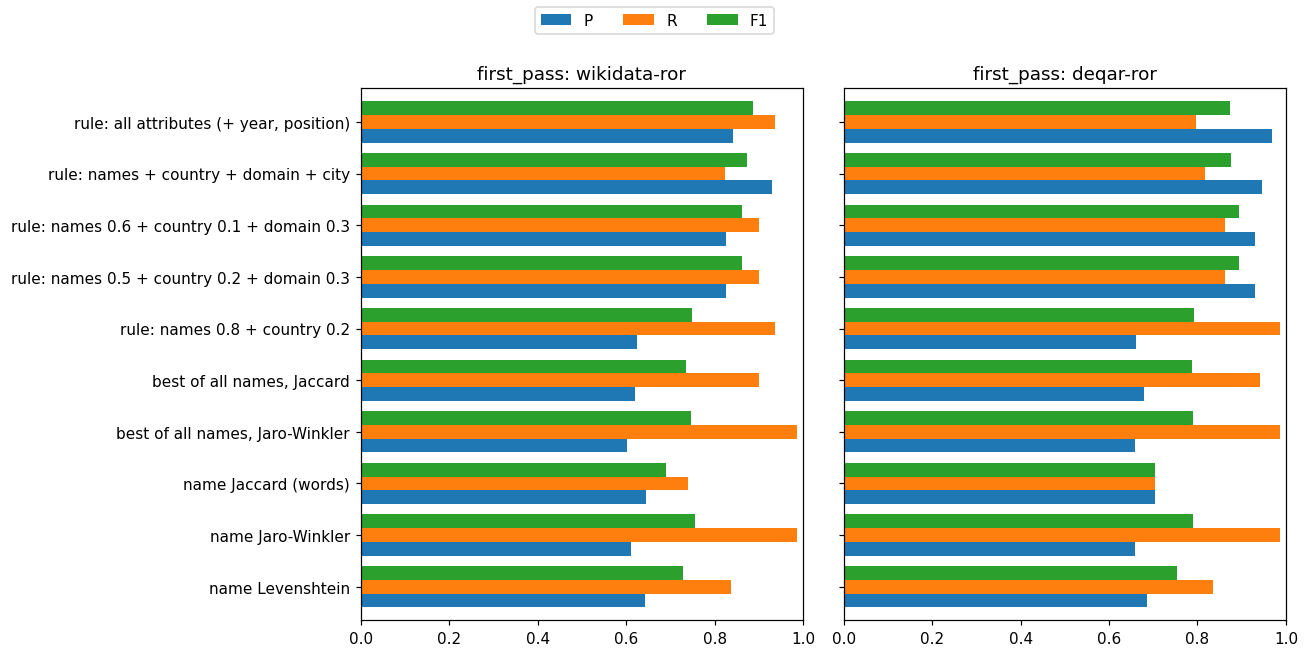

In [4]:
plot_matching(matching, "first_pass")

## Final run: every name measure alone, then rules with more attributes

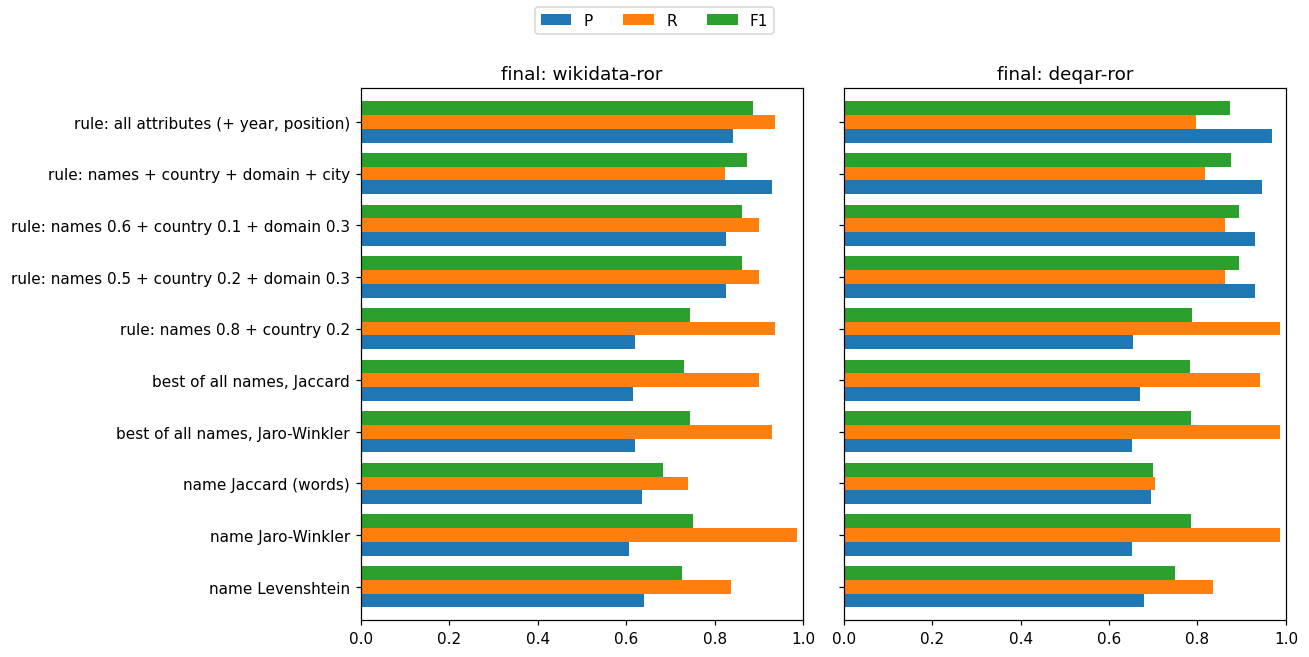

In [5]:
plot_matching(matching, "final")

## Number of correspondences

Name-only measures produce hundreds of thousands of correspondences.

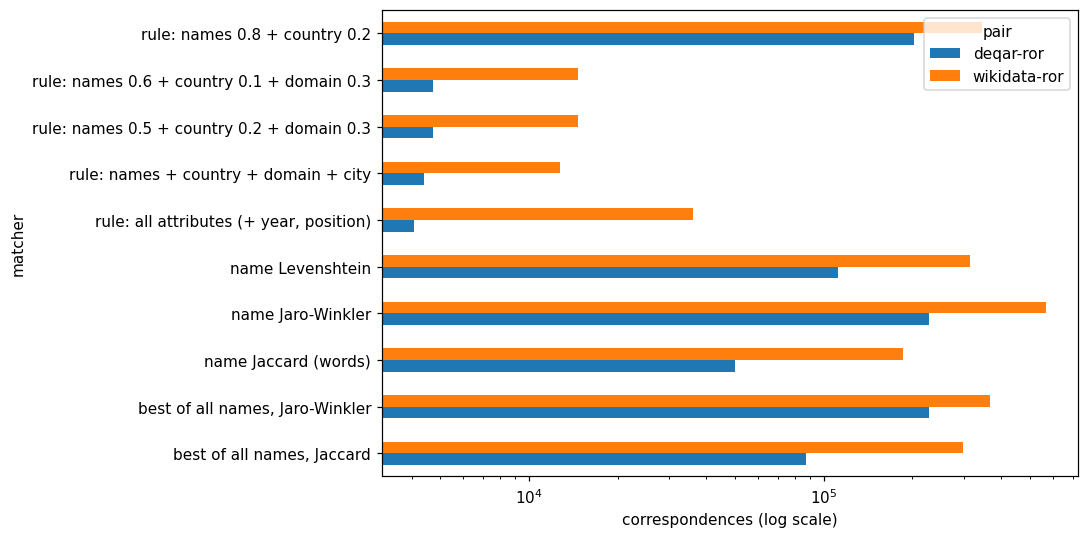

In [6]:
part = matching[matching["run"] == "final"].pivot(index="matcher", columns="pair", values="corr")
part.plot.barh(figsize=(10, 5), logx=True)
plt.xlabel("correspondences (log scale)")
plt.tight_layout()